# 02 Scenarios

Week 2 of *meter-trust*: a labelled dataset of the five classes (normal, real load change, meter fault, communication loss, false-data attack), plus a correlated outage of a whole gateway.

Each **episode** is one day (96 fifteen-minute steps) cut from the 4-week base simulation, with at most one event. The event starts between hour 6 and hour 18 of the window and lasts to its end. Episodes from days 0-20 are for training and days 21-27 for testing, so the split is by time, not at random. The rules for each class and the attacker's assumed knowledge are in the docstring of `src/scenarios.py`.

In [1]:
import sys, time
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("pandapower").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scenarios as sc, measurements as meas, estimation as est, grid

In [2]:
t0 = time.time()
data = sc.generate(n_per_class=60, n_steps=96, seed=0)   # also builds data/pf if missing
sc.save(data)                                             # data/scenarios/*.parquet
E, R, T, F, L, D = (data[k] for k in ["episodes", "readings", "true", "fresh", "labels", "defs"])
print(f"{len(E)} episodes, {len(R)} rows x {R.shape[1]} readings, {L.shape[1]} meters, {time.time() - t0:.0f} s")
E.groupby(["cls", "subtype", "split"]).size().unstack(fill_value=0)

300 episodes, 28800 rows x 84 readings, 40 meters, 27 s


split                   test  train
cls         subtype                
attack      consistent     7     23
            naive          7     23
comm_loss   dropout        5     15
            gateway        5     15
            stale          5     15
load_change down           6     23
            up             8     23
meter_fault drift          5     15
            gain           5     15
            stuck          5     15
normal      none          15     45

Labels are per meter and per step. Most cells are `normal`, because an event touches one meter (or one gateway's meters) and only after it starts:

In [3]:
counts = L.stack().value_counts().rename("meter-steps").to_frame()
counts["share"] = (counts["meter-steps"] / counts["meter-steps"].sum()).round(4)
counts

,meter-steps,share
normal,1130643,0.9815
comm_loss,11886,0.0103
attack,3890,0.0034
meter_fault,2918,0.0025
load_change,2663,0.0023


## One example per class

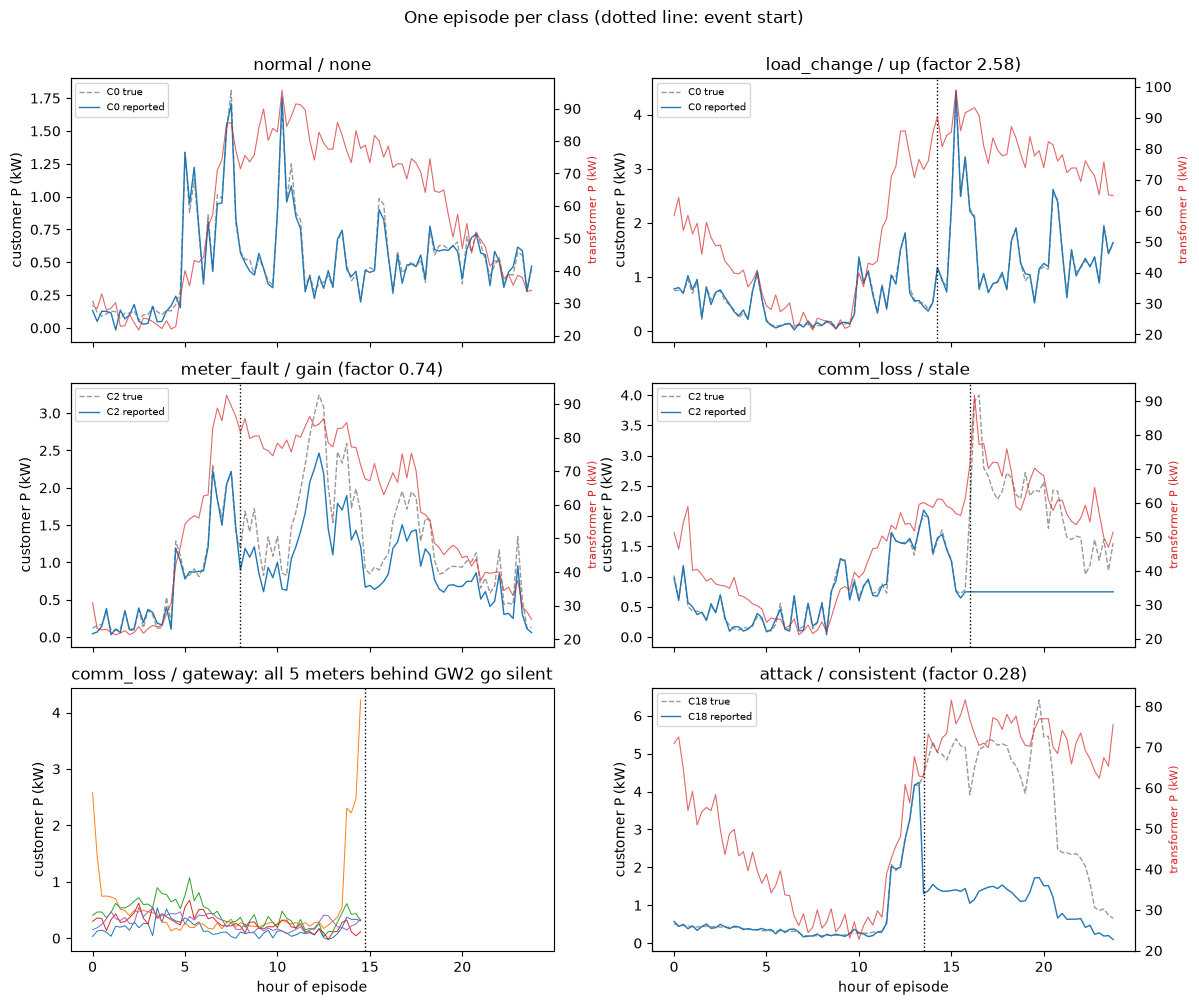

In [4]:
def pick(cls, sub):
    return E[(E.cls == cls) & (E.subtype == sub) & (E.split == "train")].index[0]

tp = D.index[(D.meter == "TRAFO") & (D.meas_type == "p")][0]
def p_of(meter):
    return D.index[(D.meter == meter) & (D.meas_type == "p")][0]

cases = [("normal", "none"), ("load_change", "up"), ("meter_fault", "gain"),
         ("comm_loss", "stale"), ("comm_loss", "gateway"), ("attack", "consistent")]
hours = np.arange(96) / 4
fig, axs = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for ax, (cls, sub) in zip(axs.flat, cases):
    ep = pick(cls, sub); e = E.loc[ep]; r, t = R.loc[ep], T.loc[ep]
    if sub == "gateway":
        for m in e.affected.split(","):
            pid = D.index[(D.meter == m) & (D.meas_type == "p")]
            if len(pid): ax.plot(hours, r[pid[0]] * 1e3, lw=0.7)
        ax.set_title(f"comm_loss / gateway: all {len(e.affected.split(','))} meters behind {e.gateway} go silent")
    else:
        meter = e.target_meter or "C" + str(D.element[p_of(L.columns[1])])
        p = p_of(meter)
        ax.plot(hours, t[p] * 1e3, color="0.6", ls="--", lw=1, label=f"{meter} true")
        ax.plot(hours, r[p] * 1e3, color="tab:blue", lw=1, label=f"{meter} reported")
        ax2 = ax.twinx()
        ax2.plot(hours, -r[tp] * 1e3, color="tab:red", lw=0.8, alpha=0.7, label="transformer reported")
        ax2.set_ylabel("transformer P (kW)", color="tab:red", fontsize=8)
        title = f"{cls} / {sub}"
        if not np.isnan(e.factor): title += f" (factor {e.factor:.2f})"
        ax.set_title(title); ax.legend(loc="upper left", fontsize=7)
    if e.event_start >= 0:
        ax.axvline(e.event_start / 4, color="k", ls=":", lw=1)
    ax.set_ylabel("customer P (kW)")
for ax in axs[-1]: ax.set_xlabel("hour of episode")
fig.suptitle("One episode per class (dotted line: event start)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "scenario_examples.png", dpi=150, bbox_inches="tight")

In the load-change panel the customer's true and reported values move together and the transformer follows. In the consistent-attack panel the reported customer reading jumps but the *true* value (dashed) does not, and the transformer, which the attacker cannot touch, stays on its old path. That gap is the only physical trace of the attack.

## Quick checks

**Energy balance.** Mean absolute gap between transformer P and the sum of customer P readings (normally just the losses plus noise). It should hold for a real load change and break for the consistent attack.

In [5]:
cust_p = D.index[(D.group == "customer_pq") & (D.meas_type == "p")]
rows = []
for ep, e in E[E.cls.isin(["normal", "load_change", "attack"])].iterrows():
    r = R.loc[ep]; t0 = max(e.event_start, 48)
    gap = (-r[tp] - r[cust_p].sum(axis=1)) * 1e3
    rows.append({"class": f"{e.cls}/{e.subtype}", "before |gap| (kW)": gap.loc[:t0 - 1].abs().mean(), "after |gap| (kW)": gap.loc[t0:].abs().mean()})
bal = pd.DataFrame(rows).groupby("class").agg(["median", "std"]).round(2)
bal

before |gap| (kW)       after |gap| (kW)      
                             median   std           median   std
class                                                           
attack/consistent              0.45  0.17             0.75  2.84
attack/naive                   0.44  0.16             1.25  0.48
load_change/down               0.41  0.08             0.45  0.14
load_change/up                 0.40  0.10             0.40  0.09
normal/none                    0.42  0.11             0.38  0.09

**WLS chi-square on event steps (preview of Week 3).** Every 4th event step of the first 5 training episodes of a few subtypes. Weights come from the *reported* values, as an operator would compute them.

In [6]:
net = grid.load_net()
out = []
for cls, sub in [("normal", "none"), ("load_change", None), ("meter_fault", "gain"),
                 ("attack", "naive"), ("attack", "consistent")]:
    sel = E[(E.cls == cls) & (E.split == "train") & ((E.subtype == sub) if sub else True)].head(5)
    flags = []
    for ep, e in sel.iterrows():
        for s in range(max(e.event_start, 24), 96, 4):
            v = R.loc[(ep, s)]
            sd = meas.std_devs(D, v.to_frame().T).iloc[0]
            if est.run_wls(net, D, v, sd) is not None:
                flags.append(est.chi2_test(net)["flag"])
    out.append({"class": f"{cls}/{sub or 'up+down'}", "steps": len(flags), "chi2 flag rate": np.mean(flags)})
pd.DataFrame(out).set_index("class").round(2)

,steps,chi2 flag rate
class,,
normal/none,90,0.00
load_change/up+down,55,0.05
meter_fault/gain,64,0.31
attack/naive,57,0.60
attack/consistent,54,0.33


## What this shows, and a correction to the plan

- The generator gives 300 labelled episodes (60 per class), with every subtype in both the training and the test weeks.
- A real load change keeps the energy balance at the transformer. The consistent attack breaks it by the size of the faked change. That is the difference the plan expected.
- **The plan expected the WLS residual test to be blind to the consistent attack. It is not, here.** The transformer meter is one of the WLS inputs, so a faked customer reading that the transformer does not confirm raises the chi-square statistic: it flags a sizeable share of consistent-attack steps, against about 5 % for real load changes. In this setup the residual test and the energy balance use the same information. The attack is invisible to WLS only if the attacker can also change the transformer reading, or if the faked change is small next to the meter noise. Week 3 should sweep the attack size and say this plainly, instead of claiming the residual test is blind.
- A stuck meter and a stale link report the same values. They differ only in the `fresh` flag (a stuck meter keeps sending new timestamps). Detectors may use that flag, because a real head-end has it.
- Limits: events last to the end of the one-day episode; there is at most one event per episode; the transformer never fails; and stuck and stale values repeat the last noisy reading exactly.